**Praktikum Week 9 Mata Kuliah Kecerdasan Buatan** <br>
Materi: Neural Network <br>
Nama: Oktova Yoga Praditia Samosir
NIM :42324001

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 3419s 20us/step


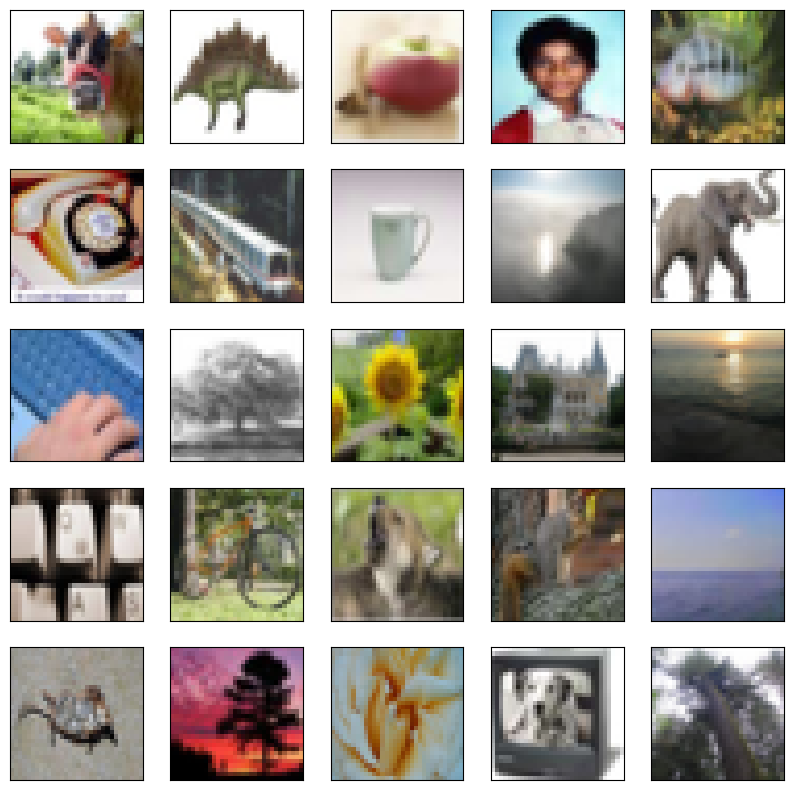

In [4]:
import tensorflow as tf
from tensorflow.keras.datasets import cifar100
import matplotlib.pyplot as plt

# Load dataset Fashion MNIST
(train_images, train_labels), (test_images, test_labels) = cifar100.load_data()

# Normalize nilai piksel gambar ke rentang [0,1]
train_images = train_images / 255.0
test_images = test_images / 255.0

# Melihat contoh gambar
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap='gray')
plt.show()


pada cel pertama ini, kita mengimpor library tensorflow, matplotlib, serta memuat dataset CIFAR-100 ke dalam data training dan testing. Setelah itu, nilai piksel gambar dinormalisasi dengan membaginya menggunakan 255.0 agar nilainya berada di rentang 0 sampai 1. Hal ini dilakukan supaya proses pelatihan model nantinya bisa lebih stabil dan cepat konvergen.

In [7]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense

# Membuat model Neural Network
model = Sequential([
    Flatten(input_shape=(32, 32, 3)),  # Mengubah gambar 28x28 menjadi vektor 1D dengan panjang 784
    Dense(128, activation='relu'),  # Hidden layer dengan 128 neuron
    Dense(100, activation='softmax')  # Output layer dengan 10 neuron untuk klasifikasi 10 kategori
])

# Melihat ringkasan arsitektur model
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 100)            │        12,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 406,244 (1.55 MB)

 Trainable params: 406,244 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

pada cel ini digunakan untuk membuat arsitektur neural network secara berurutan menggunakan model Sequential. di dalamnya terdapat layer Flatten untuk mengubah ukuran gambar 32x32 piksel RGB menjadi bentuk vektor 1 dimensi, yang kemudian dihubungkan ke hidden layer dan output layer untuk klasifikasi.

In [8]:
# Kompilasi model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Melatih model dengan data training
history = model.fit(train_images, train_labels, epochs=10, validation_data=(test_images, test_labels))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.0356 - loss: 4.3449 - val_accuracy: 0.0486 - val_loss: 4.1930
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.0557 - loss: 4.1639 - val_accuracy: 0.0571 - val_loss: 4.1325
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.0610 - loss: 4.1230 - val_accuracy: 0.0615 - val_loss: 4.1071
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.0650 - loss: 4.0975 - val_accuracy: 0.0652 - val_loss: 4.0916
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.0673 - loss: 4.0805 - val_accuracy: 0.0652 - val_loss: 4.0831
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.0680 - loss: 4.0675 - val_accuracy: 0.0660 - val_loss: 4.0745
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.0685 - loss: 4.0577 - val_accuracy: 0.0662 - val_loss: 4.0685
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.0696 - loss: 4.0498 - 

Pada tahap ini, model dikompilasi memakai optimizer Adam, fungsi loss sparse_categorical_crossentropy (karena labelnya berupa angka integer), dan metrik accuracy. Setelah dikompilasi, model dilatih menggunakan fungsi model.fit sebanyak 10 epoch dengan data pengujian yang dijadikan sebagai data validasi di setiap epoch-nya.

In [9]:
# Evaluasi model dengan data pengujian
test_loss, test_acc = model.evaluate(test_images, test_labels)

print(f'\nTest accuracy: {test_acc}')


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0669 - loss: 4.0541

Test accuracy: 0.06689999997615814


Bagian ini berfungsi untuk menguji performa model yang sudah selesai dilatih dengan memanggil fungsi model.evaluate pada data testing. nilai test accuracy kemudian dicetak untuk melihat seberapa baik model dalam mengenali data baru

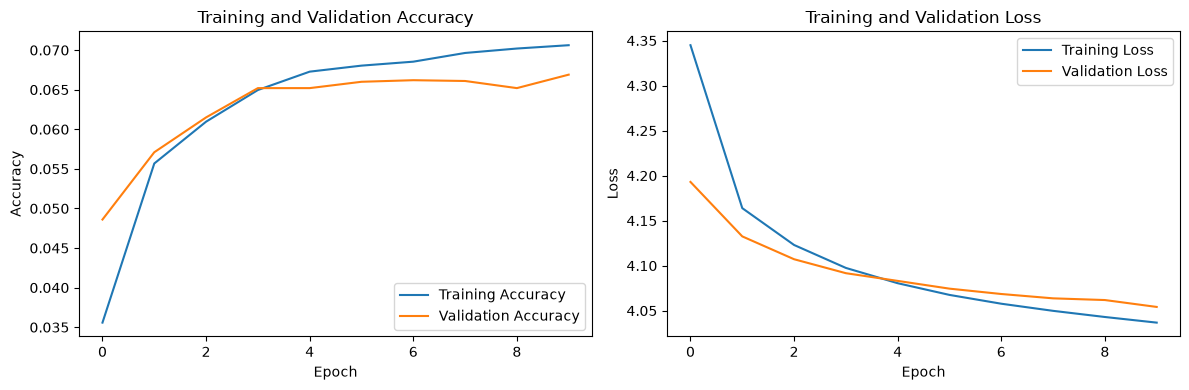

In [10]:
# Mendefinisikan fungsi untuk memvisualisasikan akurasi dan loss
def plot_history(history):
    # Plot akurasi
    plt.figure(figsize=(12, 4))

    # Plot Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')

    # Tampilkan plot
    plt.tight_layout()
    plt.show()

# Memanggil fungsi visualisasi
plot_history(history)

di cel ini, dibuat fungsi plot_history menggunakan Matplotlib untuk menampilkan dua grafik secara berdampingan. grafik pertama memperlihatkan perbandingan akurasi antara data training dan validasi, sedangkan grafik kedua menampilkan perbandingan nilai loss selama 10 epoch atau perulangan

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


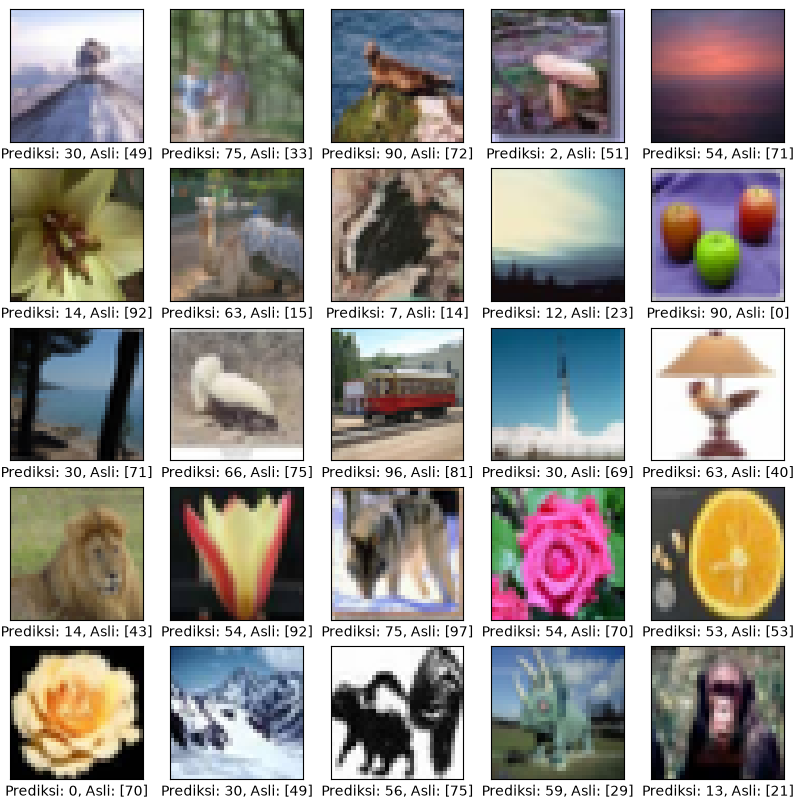

In [11]:
# Melakukan prediksi pada gambar pengujian
import numpy as np
predictions = model.predict(test_images)

# Contoh prediksi untuk 25 gambar pertama
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i], cmap='gray')
    predicted_label = np.argmax(predictions[i])
    actual_label = test_labels[i]
    plt.xlabel(f"Prediksi: {predicted_label}, Asli: {actual_label}")
plt.show()


di cel ini digunakan untuk menjalankan prediksi pada data uji menggunakan model.predict. Kemudian, 25 gambar pertama ditampilkan bersama label hasil prediksi (diambil nilai probabilitas tertingginya menggunakan np.argmax) dan label aslinya, sehingga kita bisa melihat langsung apakah tebakan model sudah sesuai atau belum.